# Лабораторная работа 4.1. Проверка гипотез

Набор данных «Пренатальная диагностика». Сначала проверим распределения количественных показателей, затем сравним рост, массу и ИМТ мальчиков и девочек.

## 1. Загрузка данных и расчёт ИМТ

В исходной таблице рост указан в сантиметрах, масса в граммах. Для ИМТ переведём их в метры и килограммы.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

alpha = 0.05
import matplotlib.pyplot as plt

df = pd.read_excel('Пренатальная диагностика.xlsx', sheet_name='исходные данные')
df = df.rename(columns={
    'vozrast': 'Возраст матери',
    'gr-dni': 'Срок гестации, дни',
    'ctr': 'КТР',
    'nt': 'ТВП',
    'rost': 'Рост, см',
    'ves': 'Масса, г',
    'pol(1-м, 0-д)': 'Пол',
})

boys = df['Пол'] == 1
girls = df['Пол'] == 0
df['ИМТ, кг/м²'] = (df['Масса, г'] / 1000) / (df['Рост, см'] / 100) ** 2

print(f'Всего: {len(df)}. Мальчиков: {boys.sum()}, девочек: {girls.sum()}.')
print(f'Пропусков: {df.isna().sum().sum()}.')
print(df.head().round(3).to_string(index=False))

Всего: 1050. Мальчиков: 577, девочек: 473.
Пропусков: 0.
 Возраст матери  Срок гестации, дни  КТР  ТВП  Рост, см  Масса, г  Пол  ИМТ, кг/м²
             18                  70   61  1.3        48      3100    0      13.455
             22                  72   50  0.9        50      3400    0      13.600
             29                  73   45  0.9        53      3500    1      12.460
             28                  74   47  1.1        50      3490    1      13.960
             31                  74   46  1.3        53      3590    0      12.780


## 2. Числовые характеристики

Пол представлен кодами двух категорий. Для него приводим частоты. Остальные столбцы количественные.

In [2]:
num = df.drop(columns='Пол')
desc = num.describe().T
desc['Размах'] = desc['max'] - desc['min']
desc['Асимметрия'] = num.skew()
desc['Эксцесс'] = num.kurt()
desc = desc.rename(columns={
    'count': 'n', 'mean': 'Среднее', 'std': 'Ст. откл.',
    'min': 'Мин.', '25%': 'Q1', '50%': 'Медиана', '75%': 'Q3', 'max': 'Макс.',
})
print(desc.round(3).to_string())

                         n   Среднее  Ст. откл.      Мин.        Q1   Медиана        Q3     Макс.    Размах  Асимметрия  Эксцесс
Возраст матери      1050.0    28.682      5.406    16.000    25.000    28.000    33.000    45.000    29.000       0.279   -0.596
Срок гестации, дни  1050.0    88.765      6.315    70.000    84.000    88.000    93.000   108.000    38.000       0.163   -0.350
КТР                 1050.0    64.126     10.450    45.000    56.000    64.000    72.000    85.000    40.000       0.036   -0.817
ТВП                 1050.0     1.337      0.398     0.300     1.100     1.300     1.600     2.800     2.500       0.330    0.303
Рост, см            1050.0    51.698      2.087    45.000    50.000    52.000    53.000    60.000    15.000       0.231    0.819
Масса, г            1050.0  3435.779    399.315  2410.000  3150.000  3430.000  3700.000  5040.000  2630.000       0.326    0.385
ИМТ, кг/м²          1050.0    12.830      1.018     8.686    12.111    12.801    13.418    18.117

## 3. Проверка на нормальность

У нормального распределения асимметрия и эксцесс равны нулю. На гистограммы наложим нормальные кривые с выборочными средними и стандартными отклонениями.

Для критерия Шапиро–Уилка H₀ предполагает нормальное распределение показателя. H₁ предполагает отклонение от нормального распределения. Уровень значимости равен 0,05.

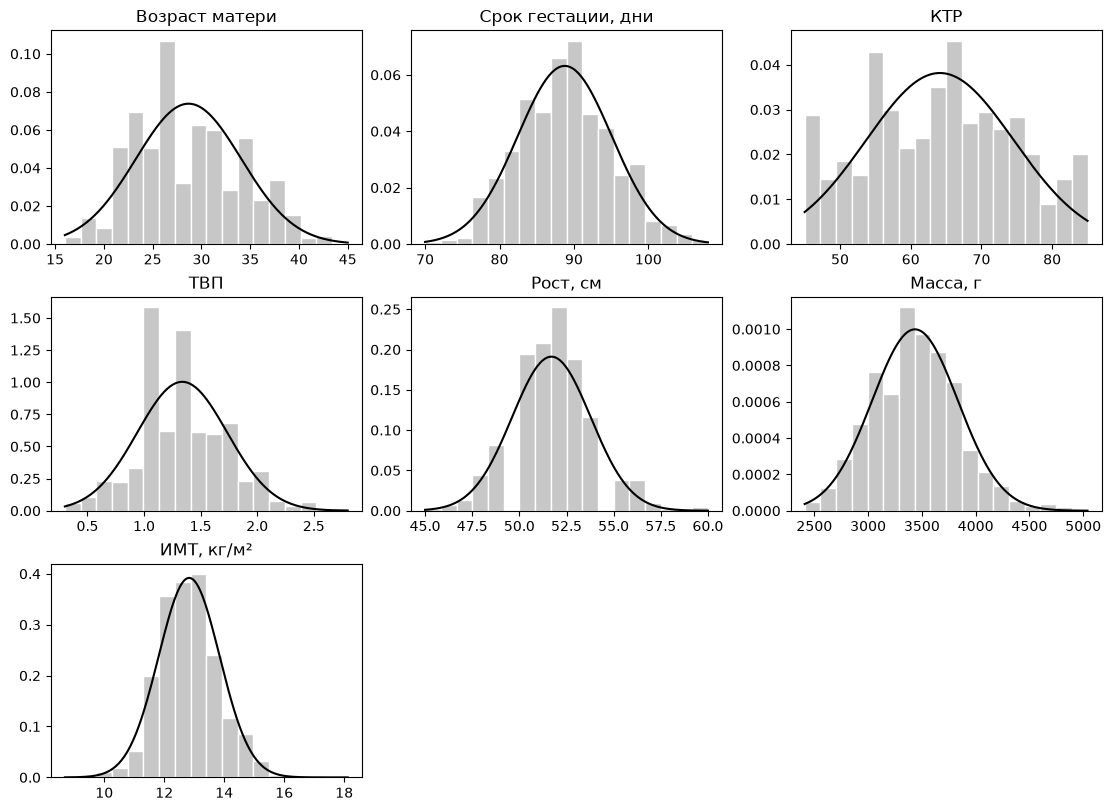

        Показатель      W         p        Вывод
    Возраст матери 0.9808 1.468e-10 отклоняем H₀
Срок гестации, дни 0.9927 4.659e-05 отклоняем H₀
               КТР 0.9774 1.007e-11 отклоняем H₀
               ТВП 0.9858 1.496e-08 отклоняем H₀
          Рост, см 0.9727 3.697e-13 отклоняем H₀
          Масса, г  0.991  4.89e-06 отклоняем H₀
        ИМТ, кг/м² 0.9903 2.161e-06 отклоняем H₀


In [3]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8), layout='constrained')
rows = []

for col, ax in zip(num, axes.flat):
    x = num[col].dropna()
    grid = np.linspace(x.min(), x.max(), 200)
    ax.hist(x, bins=18, density=True, color='0.78', edgecolor='white')
    ax.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), color='black')
    ax.set_title(col)

    w, p = stats.shapiro(x)
    decision = 'отклоняем H₀' if p < alpha else 'нет оснований отклонить H₀'
    rows.append([col, w, p, decision])

for ax in axes.flat[num.shape[1]:]:
    ax.set_visible(False)

plt.show()
normality = pd.DataFrame(rows, columns=['Показатель', 'W', 'p', 'Вывод'])
print(normality.to_string(index=False, float_format=lambda v: f'{v:.4g}'))

Масса и рост на гистограммах близки к колоколообразным, но форма гистограммы сама по себе не подтверждает нормальность. Возраст, рост и срок гестации записаны целыми числами. При 1050 наблюдениях критерий Шапиро–Уилка чувствителен и к небольшим отклонениям. По критерию Шапиро–Уилка нормальность отклоняется для всех семи количественных показателей.

## 4. Сравнение мальчиков и девочек

Для каждого показателя H₀ означает равенство средних в двух группах, H₁ означает различие средних. Выборки независимые, тест двусторонний. Если критерий Ливена даёт p < 0,05, используем тест Уэлча. Иначе используем t-тест Стьюдента с общей оценкой дисперсии. В обеих группах несколько сотен наблюдений, поэтому распределение выборочных средних можно приближённо считать нормальным.

In [4]:
rows = []
for col in ['Рост, см', 'Масса, г', 'ИМТ, кг/м²']:
    a = df.loc[boys, col].dropna()
    b = df.loc[girls, col].dropna()
    p_a = stats.shapiro(a).pvalue
    p_b = stats.shapiro(b).pvalue
    p_lev = stats.levene(a, b).pvalue
    equal = p_lev >= alpha
    t, p = stats.ttest_ind(a, b, equal_var=equal, alternative='two-sided')
    test = 'Стьюдент' if equal else 'Уэлч'
    decision = 'есть различие' if p < alpha else 'нет оснований отклонить H₀'
    rows.append([col, a.mean(), b.mean(), p_a, p_b, p_lev, test, t, p, decision])

res = pd.DataFrame(rows, columns=[
    'Показатель', 'Среднее М', 'Среднее Д', 'p Шапиро М', 'p Шапиро Д',
    'p Ливена', 'Тест', 't', 'p', 'Вывод',
])
print(res.to_string(index=False, float_format=lambda v: f'{v:.6g}'))

Показатель  Среднее М  Среднее Д  p Шапиро М  p Шапиро Д  p Ливена     Тест       t           p         Вывод
  Рост, см    52.0017    51.3277 6.47408e-10 2.93495e-08  0.779693 Стьюдент  5.2729 1.63051e-07 есть различие
  Масса, г    3497.46    3360.54 0.000141778   0.0148275  0.064879 Стьюдент 5.60751 2.62468e-08 есть различие
ИМТ, кг/м²    12.9062    12.7369   0.0813575 3.88139e-08 0.0343884     Уэлч 2.70477  0.00694825 есть различие


## Вывод

У мальчиков средние рост, масса и ИМТ выше. Различия составили около 0,67 см, 137 г и 0,17 кг/м² соответственно. Для всех трёх показателей p < 0,05. По росту и массе применён тест Стьюдента, по ИМТ применён тест Уэлча.